In [1]:
import pandas as pd 
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv('c:\\users\AQSAA\downloads\diabetes_risk_final.csv')

In [3]:
df.head(10)

,Patient_ID,Age,Gender,Country,Height_cm,Weight_kg,BMI,Waist_Circumference_cm,HbA1c,Fasting_Blood_Sugar,...,BMI_Extreme,BP_Invalid,Work_Age_Mismatch,Age_Group,BMI_Category,HbA1c_Category,Fasting_Sugar_Category,BP_Category,Unhealthy_Habits,Condition_Count
0,1,32,Male,Mexico,182.1,65.8,19.8,71.2,10.4,149.5,...,0,0,1,30-39,Normal,Diabetic,Diabetic,Normal,0,3
1,2,42,Male,Saudi Arabia,148.5,101.2,45.9,121.8,11.3,199.3,...,0,0,0,40-49,Obese III,Diabetic,Diabetic,Stage 2,2,3
2,3,89,Male,Argentina,158.1,94.7,37.9,131.8,6.3,219.6,...,0,1,0,80-90,Obese II,Prediabetes,Diabetic,Normal,4,2
3,4,87,Male,United States,190.9,95.9,26.3,99.1,7.4,217.7,...,0,0,0,80-90,Overweight,Diabetic,Diabetic,Elevated,4,2
4,5,27,Male,Australia,156.9,101.9,41.4,77.1,12.0,153.5,...,0,0,0,18-29,Obese III,Diabetic,Diabetic,Crisis,2,3
5,6,29,Male,Bangladesh,153.3,86.3,36.7,77.1,5.0,123.7,...,0,0,1,18-29,Obese II,Normal,Impaired,Elevated,3,3
6,7,90,Male,Germany,160.8,67.2,26.0,113.6,6.6,85.3,...,0,0,0,80-90,Overweight,Diabetic,Normal,Stage 2,1,2
7,8,80,Female,Bangladesh,190.3,116.9,32.3,67.4,6.7,65.5,...,0,0,0,80-90,Obese I,Diabetic,Normal,Stage 2,5,3
8,9,40,Female,United States,146.2,107.6,50.3,86.6,10.9,198.9,...,1,0,0,40-49,Obese III,Diabetic,Diabetic,Elevated,3,1
9,10,73,Male,Malaysia,194.2,54.8,14.5,132.0,4.9,132.6,...,1,0,0,70-79,Underweight,Normal,Diabetic,Stage 2,2,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47541 entries, 0 to 47540
Data columns (total 50 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Patient_ID                  47541 non-null  int64  
 1   Age                         47541 non-null  int64  
 2   Gender                      47541 non-null  object 
 3   Country                     47541 non-null  object 
 4   Height_cm                   47385 non-null  float64
 5   Weight_kg                   47385 non-null  float64
 6   BMI                         47541 non-null  float64
 7   Waist_Circumference_cm      47541 non-null  float64
 8   HbA1c                       47541 non-null  float64
 9   Fasting_Blood_Sugar         47541 non-null  float64
 10  Insulin_Level               47541 non-null  float64
 11  Blood_Pressure_Systolic     47541 non-null  int64  
 12  Blood_Pressure_Diastolic    47541 non-null  int64  
 13  Total_Cholesterol           475

Qusetions that analysis will answer :
    1- How does diabetes risk vary across different physical activity levels?
    2- How does diabetes risk vary across different HbA1c categories
    3- How does diabetes risk vary across different BMI categories?
    4- Which age groups have higher average diabetes risk scores?
    5-What is the overall distribution of diabetes risk among patients?
    6-Is there a relationship between BMI and HbA1c levels?
    7-How does the average diabetes risk score change across age groups?
    8- How does diabetes risk vary across different diet-quality levels?

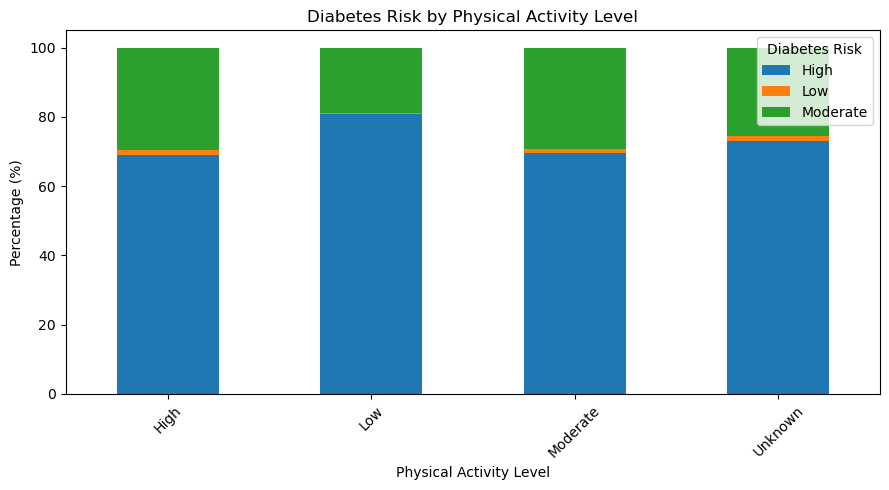

In [5]:

table = pd.crosstab(
    df["Physical_Activity_Level"],
    df["Diabetes_Risk"],
    normalize="index"
) * 100

table.plot(
    kind="bar",
    stacked=True,
    figsize=(9,5)
)

plt.title("Diabetes Risk by Physical Activity Level")
plt.xlabel("Physical Activity Level")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45)
plt.legend(title="Diabetes Risk")
plt.tight_layout()
plt.show()

This chart shows the distribution of diabetes-risk levels across different physical activity levels. It helps compare whether patients with different activity levels have different patterns of diabetes risk.

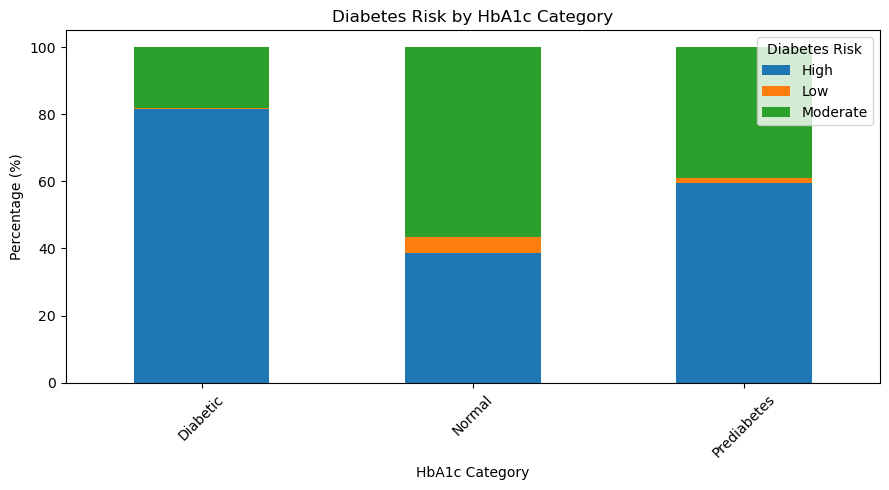

In [6]:
table = pd.crosstab(
    df["HbA1c_Category"],
    df["Diabetes_Risk"],
    normalize="index"
) * 100

table.plot(
    kind="bar",
    stacked=True,
    figsize=(9,5)
)

plt.title("Diabetes Risk by HbA1c Category")
plt.xlabel("HbA1c Category")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45)
plt.legend(title="Diabetes Risk")
plt.tight_layout()
plt.show()

This chart shows how diabetes-risk levels are distributed across different HbA1c categories. It helps identify whether patients with higher HbA1c categories tend to have a different distribution of diabetes risk.

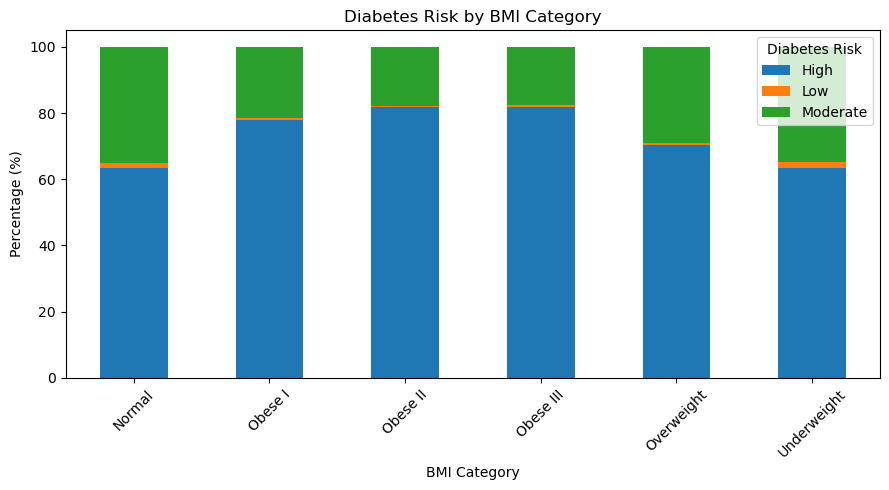

In [7]:
table = pd.crosstab(
    df["BMI_Category"],
    df["Diabetes_Risk"],
    normalize="index"
) * 100

table.plot(
    kind="bar",
    stacked=True,
    figsize=(9,5)
)

plt.title("Diabetes Risk by BMI Category")
plt.xlabel("BMI Category")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45)
plt.legend(title="Diabetes Risk")
plt.tight_layout()
plt.show()

This chart compares diabetes risk levels across different BMI categories.

X-axis: BMI Category
Y-axis: Percentage of patients
Colors: Different Diabetes Risk levels

What it tells us:
It shows whether the distribution of diabetes risk changes across BMI categories. For example, you can see if higher-BMI groups contain a larger proportion of patients in higher diabetes-risk categories.

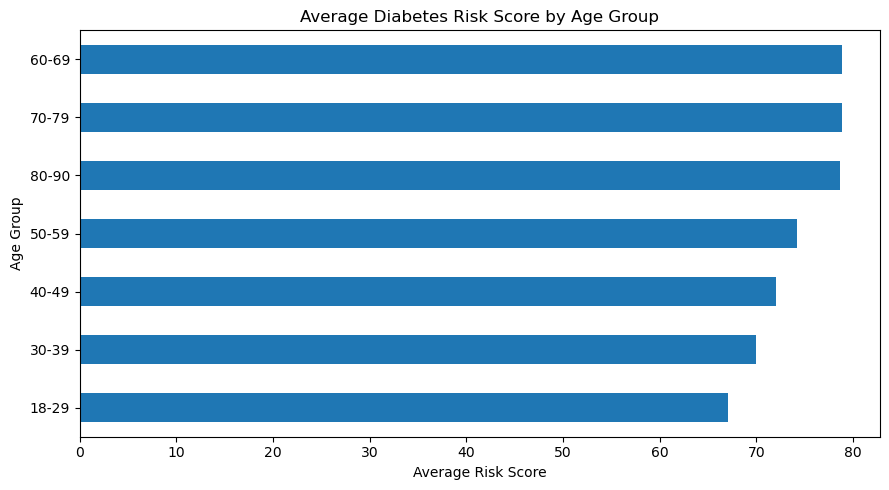

In [8]:
avg_risk = df.groupby("Age_Group")["Diabetes_Risk_Score"].mean().sort_values()

avg_risk.plot(
    kind="barh",
    figsize=(9,5)
)

plt.title("Average Diabetes Risk Score by Age Group")
plt.xlabel("Average Risk Score")
plt.ylabel("Age Group")
plt.tight_layout()
plt.show()

This chart compares the average diabetes risk score for each age group.

X-axis: Age Group
Y-axis: Average Diabetes Risk Score
Each bar represents the mean risk score for that age group.

What it tells us:
It helps identify which age groups have higher or lower average diabetes risk scores in the dataset.

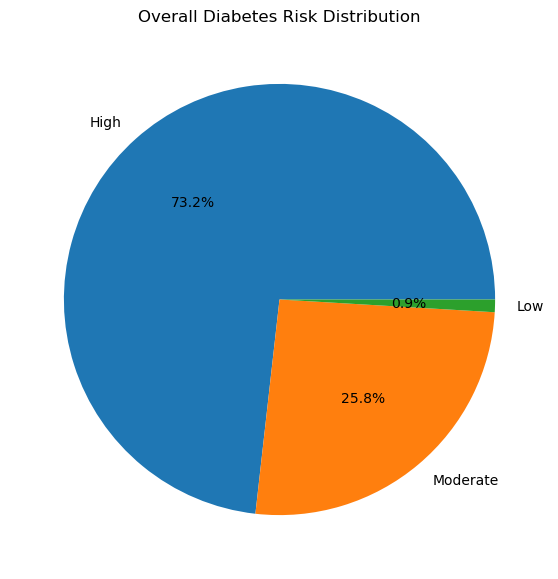

In [9]:
risk = df["Diabetes_Risk"].value_counts()

risk.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7,7)
)

plt.title("Overall Diabetes Risk Distribution")
plt.ylabel("")
plt.show()

This chart shows the percentage of patients in each diabetes-risk category.

Each slice: A diabetes-risk category
Slice size: Percentage of patients in that category
It gives a quick overview of the overall risk distribution in the dataset.

What it tells us:
You can see which diabetes-risk category contains the largest proportion of patients and how the dataset is distributed across the different risk levels.

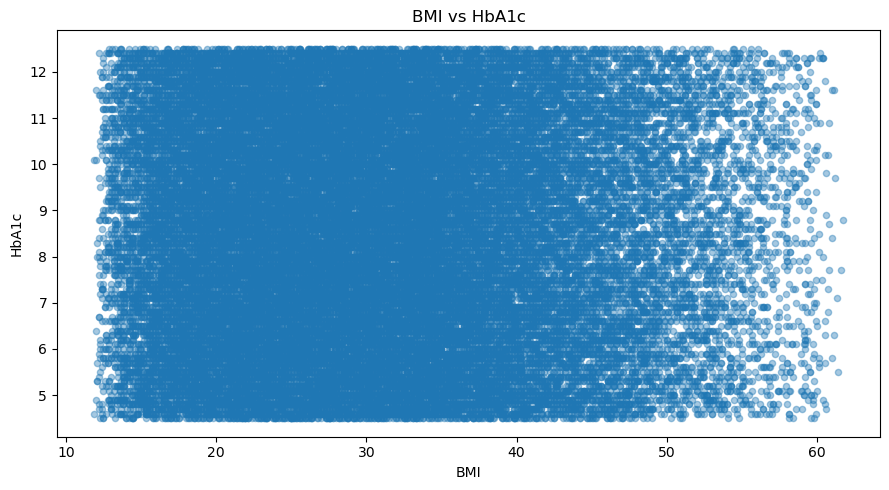

In [10]:
df.plot(
    kind="scatter",
    x="BMI",
    y="HbA1c",
    figsize=(9,5),
    alpha=0.4
)

plt.title("BMI vs HbA1c")
plt.xlabel("BMI")
plt.ylabel("HbA1c")
plt.tight_layout()
plt.show()

This scatter plot shows the relationship between BMI and HbA1c for individual patients.

X-axis: BMI
Y-axis: HbA1c
Each dot: One patient

What it tells us:
It helps us see whether patients with higher BMI also tend to have higher HbA1c values. A clear upward pattern would suggest a positive association between the two variables.

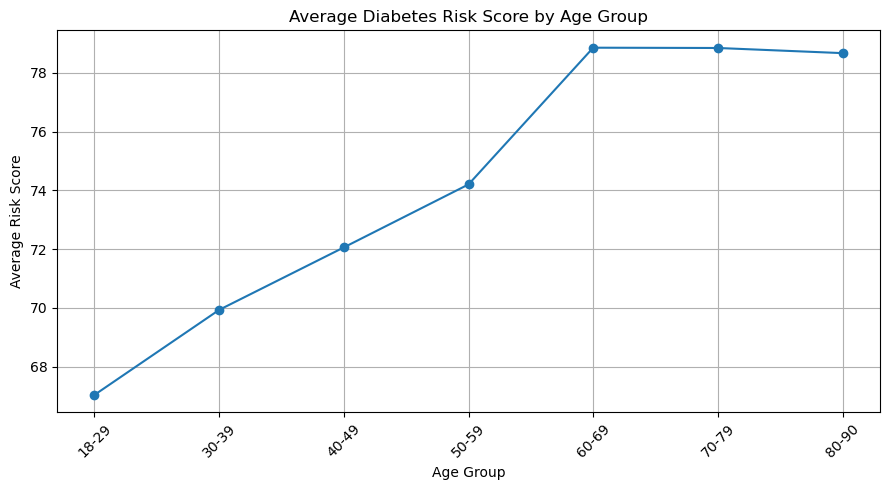

In [11]:
age_risk = df.groupby("Age_Group")["Diabetes_Risk_Score"].mean()

age_risk.plot(
    kind="line",
    marker="o",
    figsize=(9,5)
)

plt.title("Average Diabetes Risk Score by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Risk Score")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

This chart compares the average Diabetes Risk Score for different age groups.

X-axis: Age Group
Y-axis: Average Diabetes Risk Score
Each point/bar represents the average score for that age group.

What it tells us:
It helps identify which age groups have higher or lower average risk scores and whether the risk score generally changes as age increases.

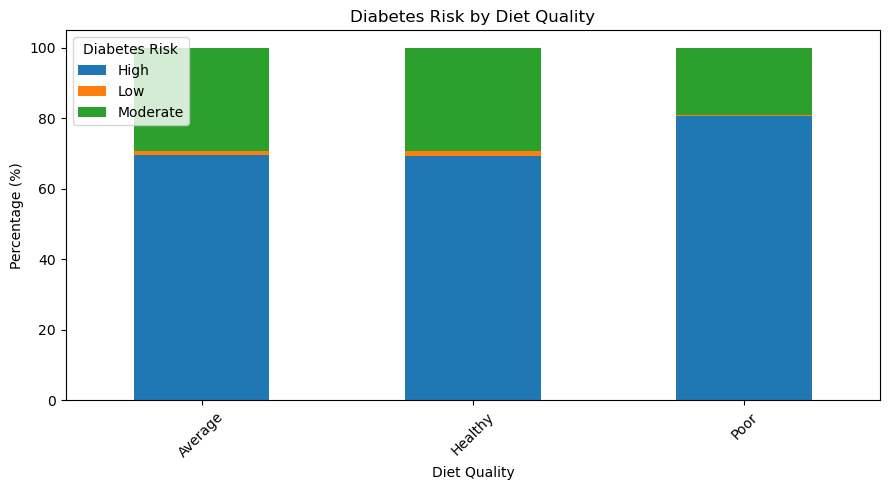

In [12]:
table = pd.crosstab(
    df["Diet_Quality"],
    df["Diabetes_Risk"],
    normalize="index"
) * 100

table.plot(
    kind="bar",
    stacked=True,
    figsize=(9,5)
)

plt.title("Diabetes Risk by Diet Quality")
plt.xlabel("Diet Quality")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45)
plt.legend(title="Diabetes Risk")
plt.tight_layout()
plt.show()

Diabetes Risk by Diet Quality

This chart compares the distribution of diabetes-risk levels across different diet-quality categories.

X-axis: Diet Quality
Y-axis: Percentage of patients
Different sections/colors: Diabetes Risk categories

What it tells us:
It helps us see whether the pattern of diabetes risk differs between patients with different diet-quality levels.

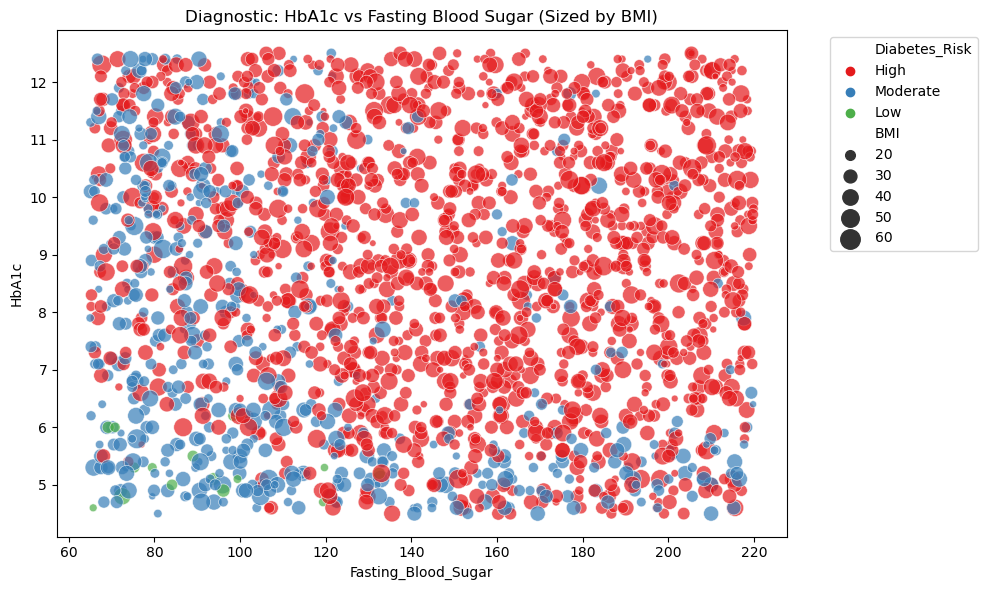

In [13]:
plt.figure(figsize=(10, 6))


sample_df = df.sample(2000, random_state=42)

sns.scatterplot(
    data=sample_df, 
    x='Fasting_Blood_Sugar', 
    y='HbA1c', 
    size='BMI', 
    sizes=(20, 200), 
    hue='Diabetes_Risk', 
    palette='Set1', 
    alpha=0.7
)

plt.title("Diagnostic: HbA1c vs Fasting Blood Sugar (Sized by BMI)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

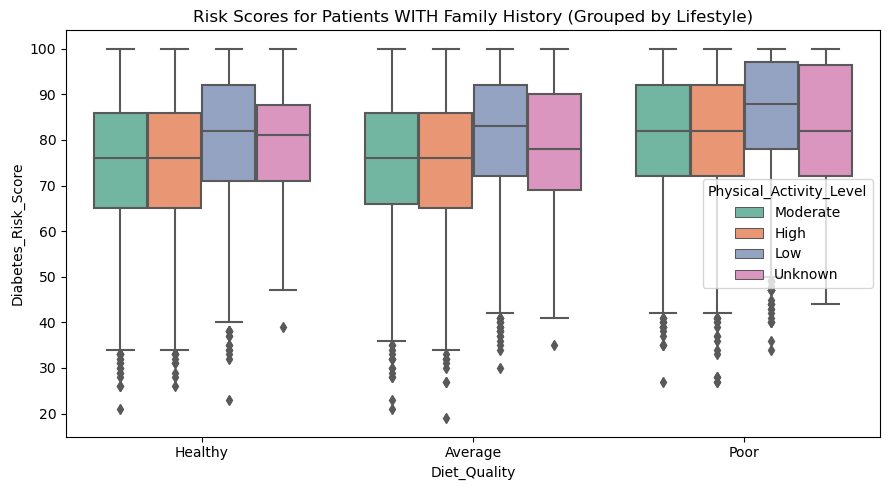

In [14]:
fh_yes = df[df['Family_History_Diabetes'] == 1]

plt.figure(figsize=(9, 5))
sns.boxplot(
    data=fh_yes, 
    x='Diet_Quality', 
    y='Diabetes_Risk_Score', 
    hue='Physical_Activity_Level', 
    palette='Set2'
)

plt.title("Risk Scores for Patients WITH Family History (Grouped by Lifestyle)")
plt.tight_layout()
plt.show()